# Selecionando os genomas

Este notebook é um resumo de como o dataset utilizado na disciplina foi montado

## Base de dados

Nós escolhemos usar a base Genome Taxonomy DataBase (GTDB) que proporciona uma classificação taxonômica confiável e uma árvore filogenética.
Nosso filo-alvo é Bacillota. Precisamos ter consciência de que a base GTDB e o NCBI podem discordar na nomenclatura. Por exemplo, para a base GTDB, Bacillota é dividido em Bacillota e Bacillota_I.

Para conseguir os dados, vamos acessar a página de dados do GTDB, dela queremos:
 
 - A árvore de bactérias
 - Tabela de identificação taxonômica
 - Tabela  de informações dos genomas

**Reprodutibilidade:** o endereço abaixo aponta para `releases/latest`, que muda a cada nova release do GTDB (árvore, nomes de táxons e genomas representativos). Em releases diferentes, a divisão de Bacillota também muda: grupos como Clostridia e Negativicutes já estiveram em filos separados (`Bacillota_A`, `Bacillota_C`), e o filtro `phylum == "Bacillota"` os excluiria. Para reproduzir exatamente esta seleção, use a pasta da release empregada na preparação em vez de `latest` (nas pastas versionadas os arquivos têm sufixo da release, por exemplo `bac120_rXXX.tree`).

A versão usada nesta análise é a 232

In [1]:
import requests
import ipywidgets as widgets
from IPython.display import display
from pathlib import Path
import pandas as pd
import numpy as np

base_url = "https://data.gtdb.aau.ecogenomic.org/releases/latest/"

# Nome do botão: arquivo a baixar
files = {
    "Baixar árvore do GTDB": "bac120.tree",
    "Baixar tabela de taxonomia": "bac120_taxonomy.tsv",
    "Baixar tabela de metadados": "bac120_metadata.tsv.gz",
}

output = widgets.Output()
buttons = []

def download_file(filename):
    with output:
        output.clear_output()
        print(f"Baixando {filename}...")

        url = base_url + filename
        output_file = Path(filename)

        try:
            with requests.get(url, stream=True, timeout=60) as response:
                response.raise_for_status()

                with open(output_file, "wb") as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)

            print(f"✓ Arquivo salvo em: {output_file.resolve()}")

        except requests.RequestException as e:
            print(f"Erro ao baixar {filename}: {e}")

# Criar os botões
for description, filename in files.items():
    button = widgets.Button(
        description=description,
        button_style="primary",
        icon="download",
        layout=widgets.Layout(width="auto")
    )

    button.on_click(lambda b, f=filename: download_file(f))
    buttons.append(button)

# Mostrar os três botões lado a lado
display(widgets.HBox(buttons), output)

Output()

In [4]:
!gunzip bac120_metadata.tsv

bac120 = pd.read_csv('bac120_metadata.tsv',sep="\t")
GTDBtax = pd.read_table('bac120_taxonomy.tsv', names=['genome','tax'])
GTDBtax[['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']] = GTDBtax['tax'].str.split(';', expand=True).apply(lambda col: col.str.replace(r'^[a-z]__', '', regex=True))
Reps_bac = bac120[bac120['accession'].isin(GTDBtax.query('phylum.str.contains("Bacillota")')['genome'])].query('gtdb_representative == "t"')

A árvore do GTDB é limitada aos genomas representativos, vamos fazer o mesmo!

In [3]:
print('Total dos representantes de Bacillota and Bacillota_I:',len(Reps_bac))

Total of Bacillota and Bacillota_I  representative members: 30966


Filos selecionados: 172
Lendo árvore original...
Árvore carregada.
Podando árvore...
Nós unifurcantes: 1309
Nós restantes: 343
Folhas restantes: 172

Filos no clado: 29
4484-113, Actinomycetota, Armatimonadota, Bacillota, Bacillota_I, Bipolaricaulota, CAYJOG01, CAZSTA01, Caldisericota, Chloroflexota, Coprothermobacterota, Cyanobacteriota, DRYD01, DUMJ01, Deinococcota, Dictyoglomota, Fusobacteriota, JAJVIF01, JAMOTN01, Margulisbacteria, Patescibacteriota, Synergistota, Sysuimicrobiota, Thermodesulfobiota, Thermotogota, UBP13, UBP15, UBP7, Vulcanimicrobiota


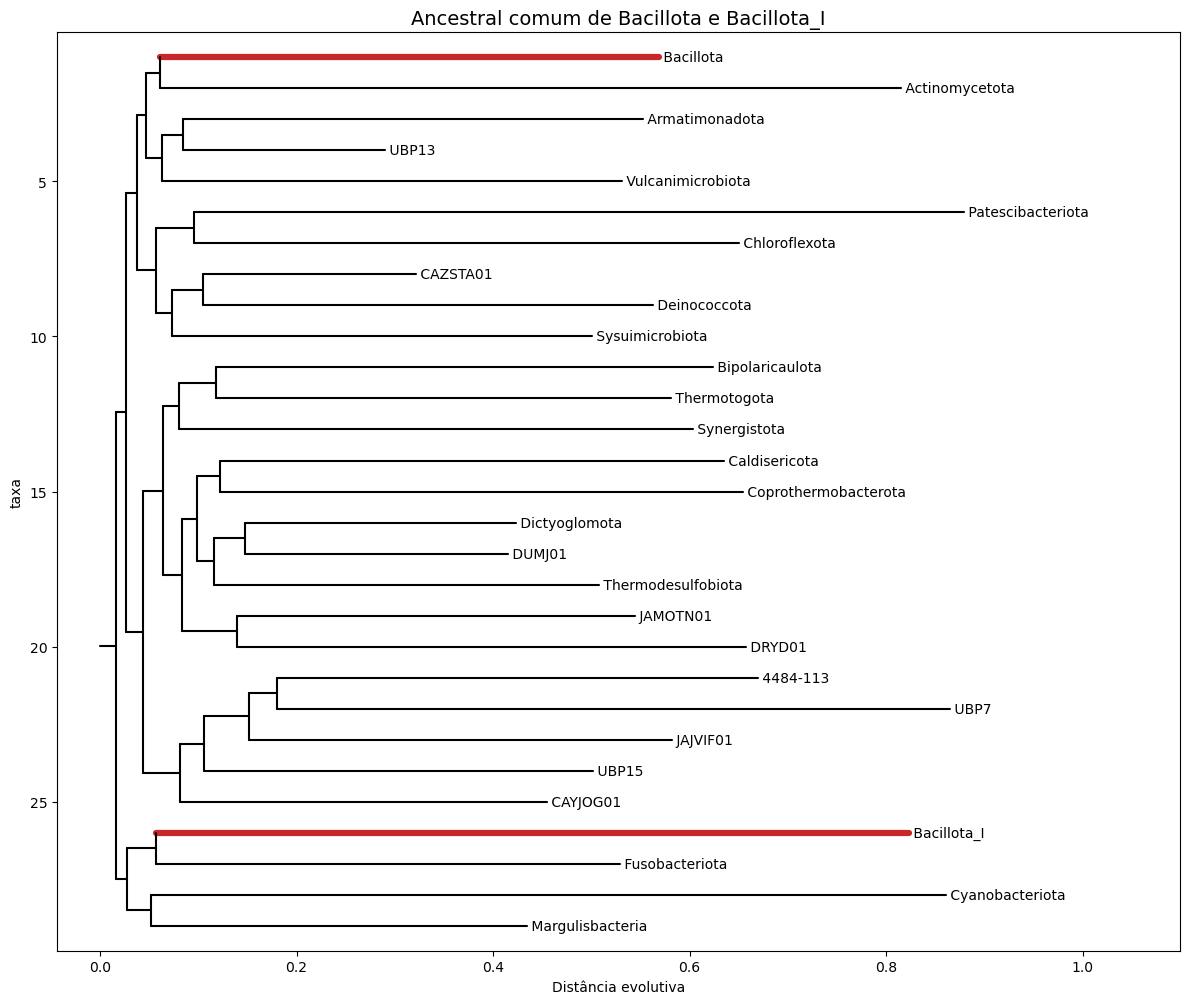

In [5]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from io import StringIO
from copy import deepcopy
from Bio import Phylo
from Bio.Phylo.Newick import Tree as NewickTree
from Bio.Phylo.BaseTree import BranchColor


# ============================================================
# 1. Selecionar um genoma representante por filo
# ============================================================

meta = bac120.merge(
    GTDBtax[['genome', 'phylum']],
    left_on='accession',
    right_on='genome',
    how='inner'
)

# Apenas representantes GTDB
meta = meta.query('gtdb_representative == "t"').copy()

# Score de qualidade
meta['score'] = (
    meta['checkm_completeness']
    - 5 * meta['checkm_contamination']
)

# Melhor genoma por filo
one_per_phylum = (
    meta.sort_values('score', ascending=False)
        .drop_duplicates('phylum')
)

# Mapeamento accession -> filo
phylum_map = (
    one_per_phylum
    .set_index('accession')['phylum']
    .to_dict()
)

keep = set(phylum_map)

print(f"Filos selecionados: {len(keep)}", flush=True)


# ============================================================
# 2. Ler a árvore original do GTDB
# ============================================================

print("Lendo árvore original...", flush=True)

with open("bac120.tree") as f:
    newick = f.read()

# Remover anotações dos nós internos
newick = re.sub(
    r"\)'[^']*'(?=:)",
    ")",
    newick
)

tree = Phylo.read(StringIO(newick), "newick")

del newick

print("Árvore carregada.", flush=True)


# ============================================================
# 3. Podar a árvore: um genoma por filo
# ============================================================

print("Podando árvore...", flush=True)

for clade in tree.find_clades(order="postorder"):

    if clade.is_terminal():
        clade._keep = clade.name in keep

    else:
        clade.clades = [
            child for child in clade.clades
            if child._keep
        ]

        clade._keep = bool(clade.clades)


# ============================================================
# 4. Remover nós unifurcantes
# ============================================================

unary_nodes = [
    node
    for node in tree.find_clades(order="postorder")
    if len(node.clades) == 1
]

print(f"Nós unifurcantes: {len(unary_nodes)}", flush=True)

# Biopython preserva as distâncias raiz-terminal
for node in unary_nodes:
    if node is not tree.root:
        tree.collapse(node)

# Contrair raiz unifurcante
while len(tree.root.clades) == 1:
    tree.root = tree.root.clades[0]

print(f"Nós restantes: {len(list(tree.find_clades()))}", flush=True)
print(f"Folhas restantes: {tree.count_terminals()}", flush=True)


# ============================================================
# 5. Renomear accessions para nomes dos filos
# ============================================================

for leaf in tree.get_terminals():
    leaf.name = phylum_map[leaf.name]


# ============================================================
# 6. Encontrar o MRCA de Bacillota e Bacillota_I
# ============================================================

target_phyla = ["Bacillota", "Bacillota_I"]

# Verificar se os dois filos estão presentes
available_phyla = {leaf.name for leaf in tree.get_terminals()}

missing = set(target_phyla) - available_phyla

if missing:
    raise ValueError(f"Filos não encontrados: {missing}")

mrca = tree.common_ancestor(target_phyla)

# Extrair apenas o clado correspondente
bacillota_tree = NewickTree(
    root=deepcopy(mrca),
    rooted=True
)

phyla = sorted(
    leaf.name
    for leaf in bacillota_tree.get_terminals()
)

print(f"\nFilos no clado: {len(phyla)}")
print(", ".join(phyla))


# ============================================================
# 7. Destacar Bacillota e Bacillota_I
# ============================================================

for leaf in bacillota_tree.get_terminals():

    if leaf.name in target_phyla:
        leaf.color = BranchColor(200, 40, 40)
        leaf.width = 3


# ============================================================
# 8. Renderizar no notebook
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, max(5, len(phyla) * 0.35))
)

Phylo.draw(
    bacillota_tree,
    axes=ax,
    do_show=False,
    show_confidence=False
)

ax.set_title(
    "Ancestral comum de Bacillota e Bacillota_I",
    fontsize=14
)

ax.set_xlabel("Distância evolutiva")

plt.tight_layout()
plt.show()

Podemos ver que Bacillota e Bacillota_I, juntos, não formam um grupo monofilético. Como precisamos de um grupo monofilético, vamos nos limitar a Bacillota, o mais numeroso dos dois.


Ainda assim, possuímos muitos genomas, para tornar a análise mais concisa, precisamos diminuir esse número

Podemos reduzir de várias maneiras, a escolhida aqui é uma simples:

 1. Criamos uma pontuação que vai nos ajudar a escolher o genoma de melhor qualidade
 2. Agrupamos por algum nível taxonômico e escolhemos o melhor genoma de cada um
 3. Verificamos o quanto perdemos com o passo 2, se for aceitável, prosseguimos
 4. Adicionamos espécies de interesse que possam ter sido descartadas no passo anterior


A pontuação que criamos é baseada em um balanço entre duas contagens:

                Pontuação = Completude - 5(Contaminação)
                
Os valores de completude e contaminação são obtidos através do programa checkM:

Completude (%): É uma estimativa de quanto do genoma foi recuperado durante a montagem. Essa estimativa é baseada em um conjunto de marcadores esperados para cada grupo de organismos, dali, tiramos a informação da proporção do genoma recuperado dada a amostra. Quanto maior a completude, mais próximo o genoma está de uma representação completa do organismo.

Contaminação (%): É uma estimativa da presença de contaminantes, ou seja, sequências que não são do organismo em questão. A presença de mais de um marcador que supostamente é de cópia única pode ser um sinal de contaminação, por exemplo. Quanto maior a contaminação estimada, menor a confiança de que todas as sequências pertençam ao organismo de interesse.

Aqui, ao calcularmos a nossa pontuação estamos dando muito peso a genomas com alta completude e baixa contaminação. Nós vamos ser bem estritos e exigir uma pontuação alta, de 70


In [16]:
#Reps_bac = Reps_bac.merge(GTDBtax, left_on = "accession", right_on = "genome", how = "left")
Reps_bac['score'] = Reps_bac['checkm2_completeness'] - 5*Reps_bac['checkm2_contamination']

# Todas as famílias
all_families = set(Reps_bac.query('phylum == "Bacillota"')['family'].dropna())

# Famílias que permaneceram após o filtro
valid_families = set(
    Reps_bac.query('phylum == "Bacillota"').loc[lambda x: x.score > 70, 'family'].dropna()
)

# Famílias que desapareceram completamente
lost_families = all_families - valid_families

print("Famílias originais:", len(all_families))
print("Famílias mantidas:", len(valid_families))
print("Famílias perdidas:", len(lost_families))

Famílias originais: 613
Famílias mantidas: 598
Famílias perdidas: 15


Quem são essas famílias perdidas?

In [25]:
print(", ".join(sorted(lost_families)))

CALMWN01, DSM-15969, DYIH01, JACMMQ01, JAEZXR01, JAGOZY01, JAJYMS01, JAQUNY01, JASBVW01, JAZPYJ01, UBA1257, UBA8921, UBA941, UPPP01, WRCU01


Podemos ver que todas são famílias sem nome definido ainda, os nomes que estamos vendo estão relacionados aos isolados, logo, aceitamos a perda destas famílias e seguimos

Logo, selecionamos um genoma por família, o que tiver a pontuação de qualidade maior

Entretanto, também selecionamos separadamente um membro de cada uma das seguintes espécies:

_Bacillus subtilis_, _Bacillus cereus_, _Lactococcus lactis_, _Staphylococcus aureus_, _Enterococcus faecalis_, _Bacillus anthracis_, _Clostridium botulinum_, _Listeria monocytogenes_ , _Streptococcus pneumoniae_, _Clostridioides difficile_, _Veillonella parvula_ e _Halanaerobium saccharolyticum_

In [34]:
Selection = Reps_bac.query('phylum == "Bacillota" and score > 70').sort_values(['score', 'accession'], ascending=[False, True]).drop_duplicates('family')

In [35]:
species_of_interest = ['Bacillus subtilis', 'Bacillus cereus', 'Lactococcus lactis', 'Staphylococcus aureus','Enterococcus faecalis', 'Bacillus anthracis','Clostridium botulinum','Listeria monocytogenes','Streptococcus pneumoniae','Clostridioides difficile','Veillonella parvula','Halanaerobium saccharolyticum']
Reps_bac['species_stripped'] = Reps_bac['species'].str.replace(r'_[A-Z]+(?=\s|$)', '', regex=True)
extras = Reps_bac.query('phylum == "Bacillota"').loc[Reps_bac.query('phylum == "Bacillota"').species_stripped.isin(species_of_interest)].sort_values('score', ascending=False).groupby('species_stripped', as_index=False).first()
Selection = pd.concat([Selection,extras]).drop_duplicates(subset='accession')

/tmp/ipykernel_2746096/1840876252.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  extras = Reps_bac.query('phylum == "Bacillota"').loc[Reps_bac.query('phylum == "Bacillota"').species_stripped.isin(species_of_interest)].sort_values('score', ascending=False).groupby('species_stripped', as_index=False).first()


In [36]:
print('Total selecionado:',len(Selection))

Total selecionado: 610


In [37]:
#Selection.to_csv('intermediate_data3.tsv',sep="\t", index= False)